In [1]:
pip install geopandas shapely

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 8.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 8.7 MB/s  0:00:02m 8.6 MB/s eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 9.3 MB/s  0:00:009.1 MB/s eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]━ 3/4 [geopandas]
Note: you may need to restart the kernel to use updated packages.


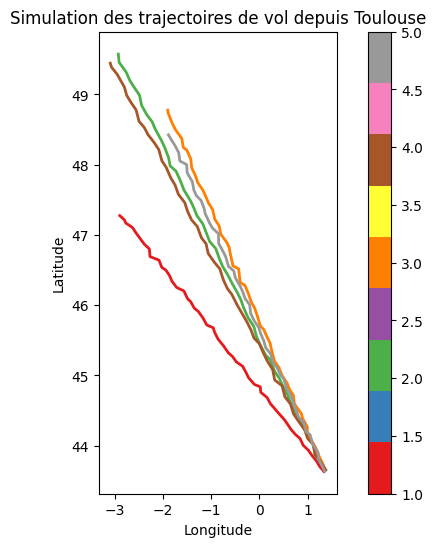

In [3]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, LineString
import numpy as np
import matplotlib.pyplot as plt

# Coordonnées de départ : Toulouse-Blagnac
tls_lon, tls_lat = 1.362, 43.630

# Fonction pour simuler une trajectoire unique
def generer_trajectoire(engine_id, nb_points=50):
    # Simulation d'un vol vers le Nord-Ouest (direction Paris/Londres)
    lons = np.linspace(tls_lon, tls_lon - np.random.uniform(2, 5), nb_points)
    lats = np.linspace(tls_lat, tls_lat + np.random.uniform(3, 6), nb_points)
    
    # Ajout d'un léger bruit aléatoire pour simuler de vrais relevés GPS
    lons += np.random.normal(0, 0.02, nb_points)
    lats += np.random.normal(0, 0.02, nb_points)
    
    # Création de la ligne géométrique (LineString)
    points = [Point(lon, lat) for lon, lat in zip(lons, lats)]
    return LineString(points)

# Génération de trajectoires pour 5 moteurs différents
donnees = []
for engine in range(1, 6):
    trajectoire = generer_trajectoire(engine_id=engine)
    donnees.append({'engine_id': engine, 'geometry': trajectoire})

# Conversion en GeoDataFrame (Standard spatial EPSG:4326 pour le GPS WGS84)
gdf = gpd.GeoDataFrame(donnees, crs="EPSG:4326")

# Affichage visuel des trajectoires
gdf.plot(column='engine_id', cmap='Set1', linewidth=2, figsize=(8, 6), legend=True)
plt.title("Simulation des trajectoires de vol depuis Toulouse")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()